# Cleaning & EDA

Decisions are recorded in `docs/design.md` (Stage 4). Leakage rules:

- **Sensor behaviour plots use train only.** Val/test readings are not inspected before final evaluation.
- **Data-quality checks run on all splits.** They are mechanical, and production runs the same checks.
- **Anomaly counts use `anomaly_labels.csv` for all splits** (documentation only).
- Train labels are used **only** to shade plots and to split normal vs anomalous minutes. They are never model inputs.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import config as cfg
import features as F

OUT_DIR = cfg.ROOT / "outputs" / "eda"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Readable defaults
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

# Fixed colour per anomaly type (validated categorical order, never cycled)
TYPE_COLORS = {
    "temp_spike": "#2a78d6", "heating_failure": "#eb6834", "fridge_power_loss": "#1baf7a",
    "compressor_stuck_on": "#eda100", "intrusion_motion": "#e87ba4", "door_open_night": "#008300",
    "door_left_open": "#6250d6",
}
DAY_TYPE_COLORS = {"tue_thu": "#2a78d6", "mon_fri": "#eb6834", "weekend": "#1baf7a"}
NORMAL, ANOMALOUS = "#9a9893", "#eb6834"
SENSOR_UNITS = {cfg.TEMP: "°C", cfg.POWER: "W", cfg.MOTION: "motion min / 15 min", cfg.DOOR: "open (0/1)"}

## 2. Data quality (all splits)

In [2]:
raw = {s: F.load_split(s) for s in cfg.SPLITS}
cleaned = {s: F.clean_split(s) for s in cfg.SPLITS}

dq = pd.DataFrame({s: F.data_quality_report(raw[s], cleaned[s]) for s in cfg.SPLITS})
dq

,train,val,test
raw_rows,20136,10042,10049
duplicate_rows,2,2,2
missing_rows,26,40,33
out_of_order,0,0,0
temp_living_room_missing_cells,139,65,125
temp_living_room_offline_min,141,92,143
temp_living_room_offline_periods,2,2,2
power_fridge_missing_cells,81,73,81
power_fridge_offline_min,81,97,102
power_fridge_offline_periods,2,2,2


**Offline detection vs the generation log.** Every sensor outage and the hub outage should show up as an offline period.
Offline minutes are 2 per outage lower than the outage length, because the 2-minute forward fill covers the first 2 minutes. In real time we cannot know yet that a gap will be long.

In [3]:
log = F.load_generation_log()
outages = log[log["kind"].isin(["sensor_outage", "hub_outage"])].copy()
outages["minutes"] = (outages["end"] - outages["start"]).dt.total_seconds() / 60 + 1

rows = []
for split in cfg.SPLITS:
    for sensor in cfg.SENSORS:
        mine = outages[(outages["split"] == split) & outages["sensor_id"].isin([sensor, "all"])]
        rows.append({
            "split": split, "sensor": sensor,
            "logged_outages": len(mine),
            "detected_offline_periods": dq.loc[f"{sensor}_offline_periods", split],
            "logged_minutes": int(mine["minutes"].sum()),
            "offline_minutes": dq.loc[f"{sensor}_offline_min", split],
        })
offline_check = pd.DataFrame(rows)
offline_check["logged_minus_2_per_outage"] = offline_check["logged_minutes"] - 2 * offline_check["logged_outages"]
offline_check

,split,sensor,logged_outages,detected_offline_periods,logged_minutes,offline_minutes,logged_minus_2_per_outage
0,train,temp_living_room,2,2,145,141,141
1,train,power_fridge,2,2,85,81,81
2,train,motion_hallway,2,2,103,99,99
3,train,door_front,2,2,68,64,64
4,val,temp_living_room,2,2,96,92,92
5,val,power_fridge,2,2,101,97,97
6,val,motion_hallway,2,2,57,53,53
7,val,door_front,2,2,80,76,76
8,test,temp_living_room,2,2,147,143,143
9,test,power_fridge,2,2,106,102,102


## 3. Injected anomalies (labels, all splits)

In [4]:
labels = F.load_labels()
labels["minutes"] = (labels["end"] - labels["start"]).dt.total_seconds() / 60 + 1

summary = labels.pivot_table(index=["sensor_id", "anomaly_type"], columns="split", values="minutes",
                             aggfunc=["count", "sum"])[[(a, s) for a in ("count", "sum") for s in cfg.SPLITS]]
summary.columns = [f"{s}_{'anomalies' if a == 'count' else 'minutes'}" for a, s in summary.columns]
summary.loc[("total", ""), :] = summary.sum()
summary.astype(int)

train_anomalies  val_anomalies  \
sensor_id        anomaly_type                                          
door_front       door_left_open                     3              2   
                 door_open_night                    3              2   
motion_hallway   intrusion_motion                   3              2   
power_fridge     compressor_stuck_on                3              2   
                 fridge_power_loss                  3              2   
temp_living_room heating_failure                    3              2   
                 temp_spike                         3              2   
total                                              21             14   

                                      test_anomalies  train_minutes  \
sensor_id        anomaly_type                                         
door_front       door_left_open                    2             94   
                 door_open_night                   2             14   
motion_hallway   intrusion_motion                  2             65   
power_fridge     compressor_stuck_on               2            231   
                 fridge_power_loss                 2            269   
temp_living_room heating_failure                   2            801   
                 temp_spike                        2              4   
total                                             14           1478   

                                      val_minutes  test_minutes  
sensor_id        anomaly_type                                    
door_front       door_left_open               106            90  
                 door_open_night                5            10  
motion_hallway   intrusion_motion              37            37  
power_fridge     compressor_stuck_on          127           147  
                 fridge_power_loss            222           111  
temp_living_room heating_failure              493           523  
                 temp_spike                     2             5  
total                                         992           923

In [5]:
split_minutes = {s: len(cleaned[s]) for s in cfg.SPLITS}
share = labels.groupby(["split", "sensor_id"])["minutes"].sum().unstack().reindex(list(cfg.SPLITS))
share = share.div(pd.Series(split_minutes), axis=0) * 100
share["any_sensor"] = share.sum(axis=1)
share.round(2).rename_axis("% of split minutes", axis=1)

% of split minutes,door_front,motion_hallway,power_fridge,temp_living_room,any_sensor
split,,,,,
train,0.54,0.32,2.48,3.99,7.33
val,1.10,0.37,3.46,4.91,9.84
test,0.99,0.37,2.56,5.24,9.16


## 4. Train features

In [6]:
train = cleaned["train"]
baseline = F.fit_temp_baseline(train)            # learned on train only (groups: tue_thu vs occupied)
feat = F.build_features(train, baseline)
lab_min = F.minute_labels(feat.index, labels[labels["split"] == "train"])
feat = feat.join(lab_min)

def normal_mask(sensor):
    # Minutes with no anomaly on this sensor (anomalies on other sensors don't change it)
    return feat["anomaly_sensor"] != sensor

baseline.unstack(0).round(2).T

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
baseline_group,,,,,,,,,,,,,,,,,,,,,
occupied,20.26,19.84,19.50,19.23,19.01,18.83,18.79,20.34,20.81,20.92,...,21.42,21.40,21.32,21.27,21.17,21.14,21.11,21.10,21.08,20.80
tue_thu,20.18,19.80,19.46,19.18,18.99,18.81,18.79,20.33,20.74,20.35,...,19.01,18.89,18.72,18.70,20.19,20.79,20.94,20.99,20.99,20.65


## Plot 1: one train week with anomalies

Each anomaly is shaded on **its own sensor's** panel. Spans shorter than 40 min are widened to 40 min so they stay visible (only on the plot).

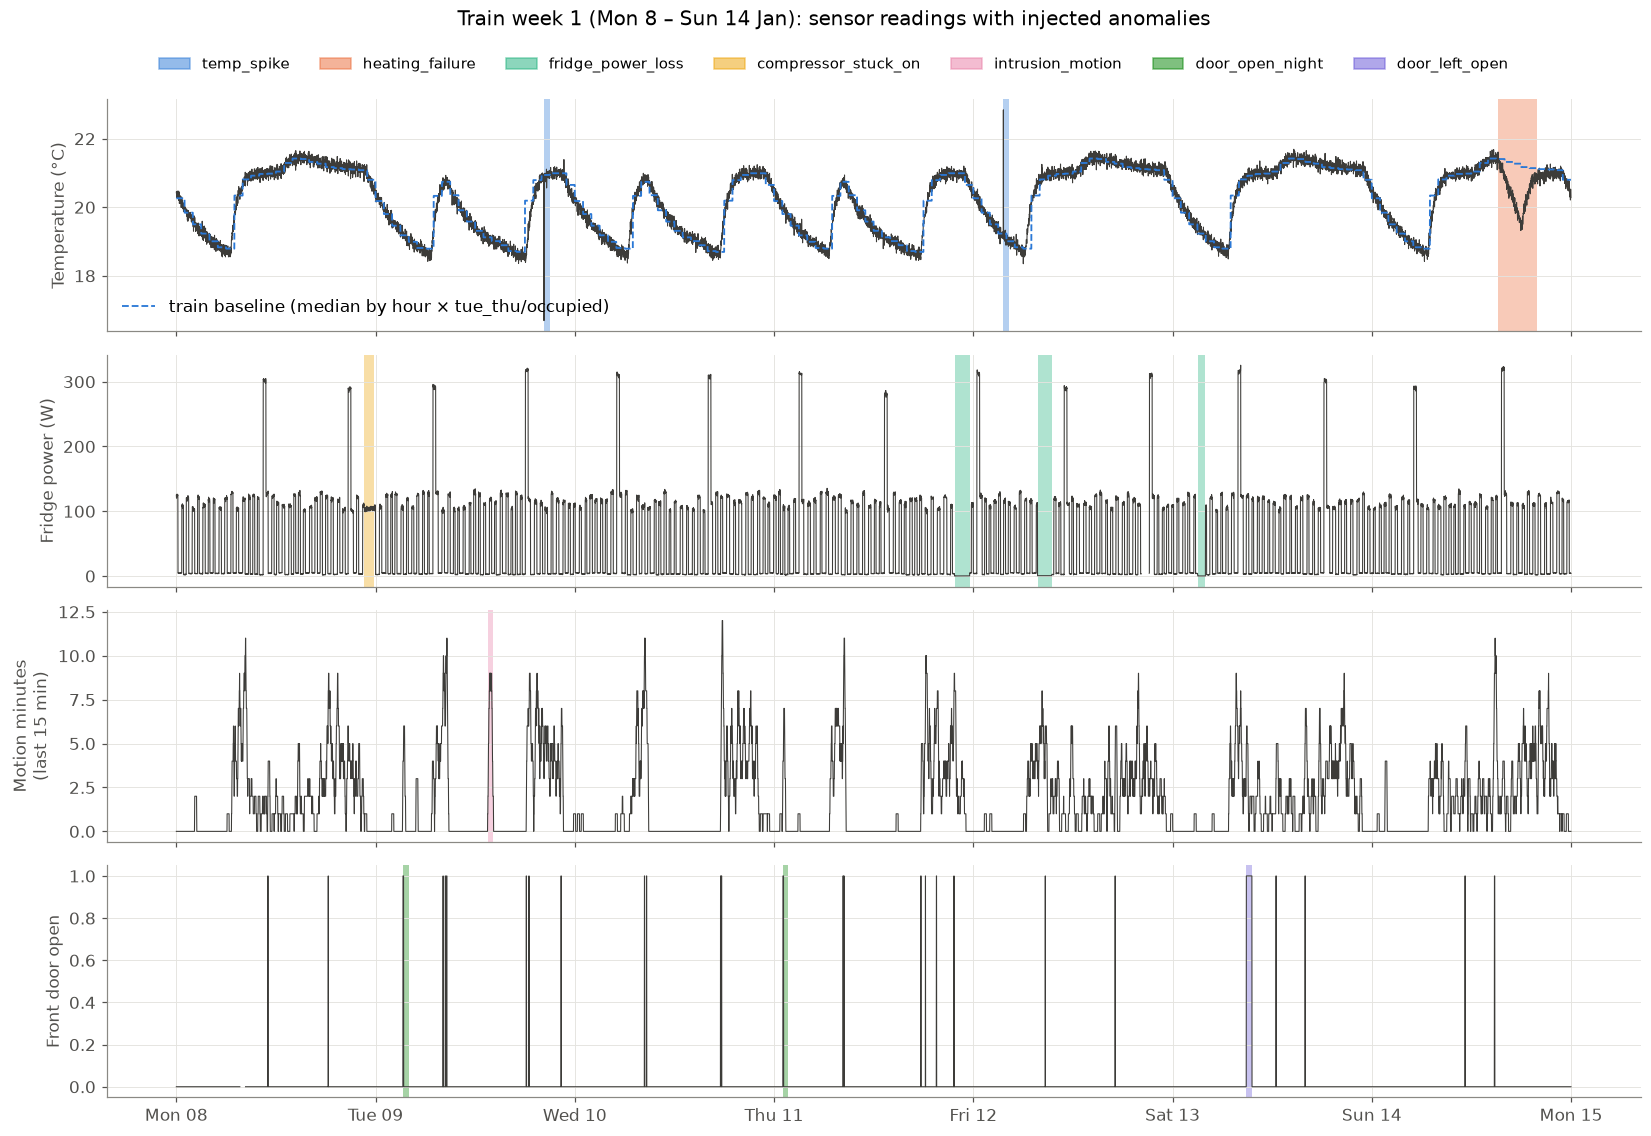

In [7]:
week = feat.loc["2024-01-08":"2024-01-14"]
week_labels = labels[(labels["split"] == "train") & (labels["start"] < "2024-01-15")]

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
panels = [
    (cfg.TEMP, week[cfg.TEMP], "Temperature (°C)"),
    (cfg.POWER, week[cfg.POWER], "Fridge power (W)"),
    (cfg.MOTION, week["motion_15"], "Motion minutes\n(last 15 min)"),
    (cfg.DOOR, week[cfg.DOOR], "Front door open"),
]
for ax, (sensor, series, ylabel) in zip(axes, panels):
    ax.plot(series.index, series, color="#3d3c39", linewidth=0.7)
    ax.set_ylabel(ylabel)
    for _, a in week_labels[week_labels["sensor_id"] == sensor].iterrows():
        end = max(a["end"], a["start"] + pd.Timedelta("40min"))
        ax.axvspan(a["start"], end, color=TYPE_COLORS[a["anomaly_type"]], alpha=0.35, linewidth=0)
axes[0].plot(week.index, week["temp_baseline"], color="#2a78d6", linewidth=1.2, linestyle="--",
             label="train baseline (median by hour × tue_thu/occupied)")
axes[0].legend(loc="lower left")

handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in TYPE_COLORS.values()]
fig.legend(handles, TYPE_COLORS.keys(), loc="upper center", ncol=7, fontsize=10, bbox_to_anchor=(0.5, 1.0))
axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d"))
fig.suptitle("Train week 1 (Mon 8 – Sun 14 Jan): sensor readings with injected anomalies", y=1.03, fontsize=13)
fig.tight_layout()
fig.savefig(OUT_DIR / "1_train_week.png", bbox_inches="tight")
plt.show()

## Plot 2: daily profile by day type (train, normal minutes only)

Minutes inside an anomaly on that sensor are excluded, so the profiles show normal behaviour.

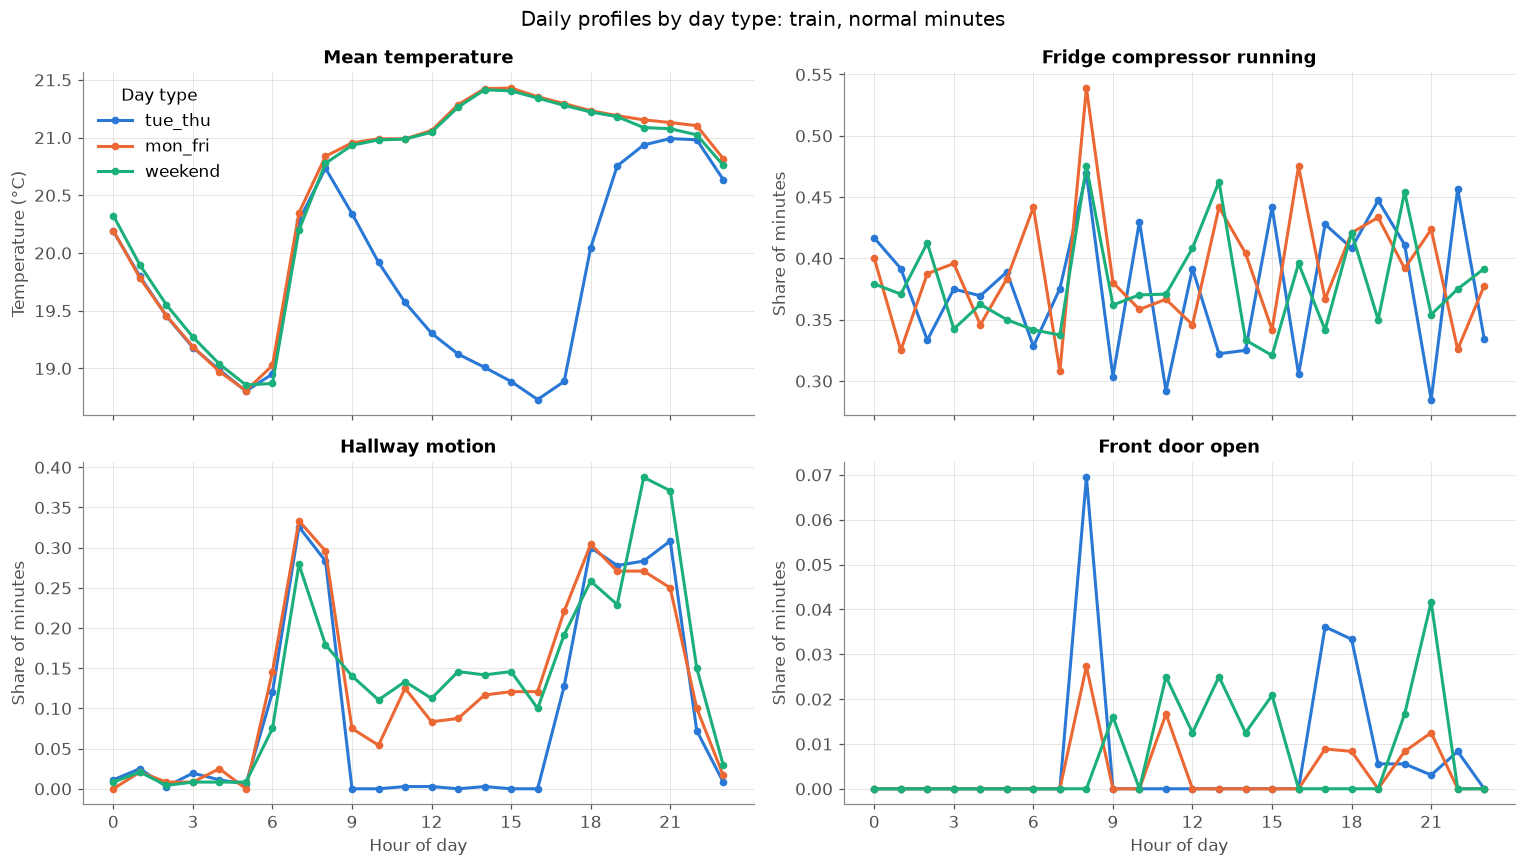

In [8]:
profiles = [
    (cfg.TEMP, feat[cfg.TEMP], "Temperature (°C)", "Mean temperature"),
    (cfg.POWER, (feat["fridge_mode"] == "running").where(feat["fridge_mode"].notna()), "Share of minutes",
     "Fridge compressor running"),
    (cfg.MOTION, feat[cfg.MOTION], "Share of minutes", "Hallway motion"),
    (cfg.DOOR, feat[cfg.DOOR], "Share of minutes", "Front door open"),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (sensor, series, ylabel, title) in zip(axes.flat, profiles):
    ok = normal_mask(sensor)
    for dt, color in DAY_TYPE_COLORS.items():
        sel = ok & (feat["day_type"] == dt)
        hourly = series[sel].groupby(feat.loc[sel, "hour"]).mean()
        ax.plot(hourly.index, hourly.values, color=color, linewidth=2, marker="o", markersize=4, label=dt)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(0, 24, 3))
for ax in axes[1]:
    ax.set_xlabel("Hour of day")
axes[0, 0].legend(title="Day type")
fig.suptitle("Daily profiles by day type: train, normal minutes", fontsize=13)
fig.tight_layout()
fig.savefig(OUT_DIR / "2_daily_profiles.png", bbox_inches="tight")
plt.show()

## Plot 3: distributions, normal vs anomalous minutes (train)

"Anomalous" means minutes inside an anomaly **on that sensor**. Densities use a log y-axis because anomalous minutes are rare.

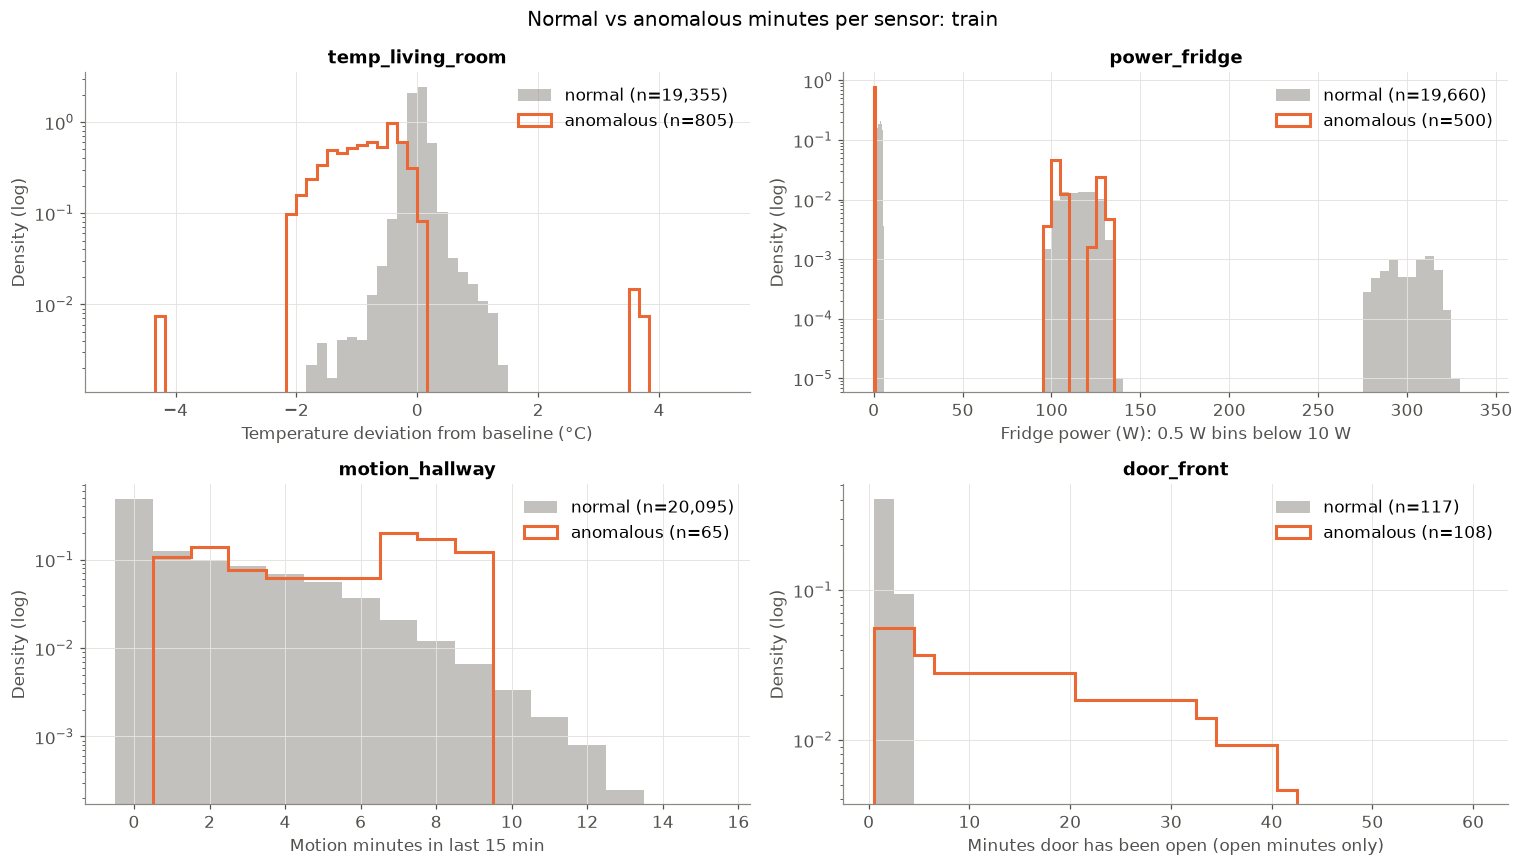

In [9]:
dists = [
    (cfg.TEMP, "temp_dev", "Temperature deviation from baseline (°C)", np.linspace(-5, 5, 61)),
    (cfg.POWER, cfg.POWER, "Fridge power (W): 0.5 W bins below 10 W", np.r_[np.arange(0, 10, 0.5), np.arange(10, 345, 5)]),
    (cfg.MOTION, "motion_15", "Motion minutes in last 15 min", np.arange(-0.5, 16, 1)),
    (cfg.DOOR, "door_open_minutes", "Minutes door has been open (open minutes only)", np.arange(0.5, 62, 2)),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (sensor, col, xlabel, bins) in zip(axes.flat, dists):
    values = feat[col]
    if sensor == cfg.DOOR:
        values = values[values > 0]
    is_anom = ~normal_mask(sensor).reindex(values.index)
    ax.hist(values[~is_anom].dropna(), bins=bins, density=True, histtype="stepfilled",
            color=NORMAL, alpha=0.6, label=f"normal (n={int((~is_anom).sum()):,})")
    ax.hist(values[is_anom].dropna(), bins=bins, density=True, histtype="step",
            color=ANOMALOUS, linewidth=2, label=f"anomalous (n={int(is_anom.sum()):,})")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density (log)")
    ax.set_title(sensor)
    ax.legend()
fig.suptitle("Normal vs anomalous minutes per sensor: train", fontsize=13)
fig.tight_layout()
fig.savefig(OUT_DIR / "3_distributions.png", bbox_inches="tight")
plt.show()

## Plot 4: fridge run lengths per mode (train)

One value per completed idle / running period. A period is "anomalous" if it overlaps a fridge anomaly.

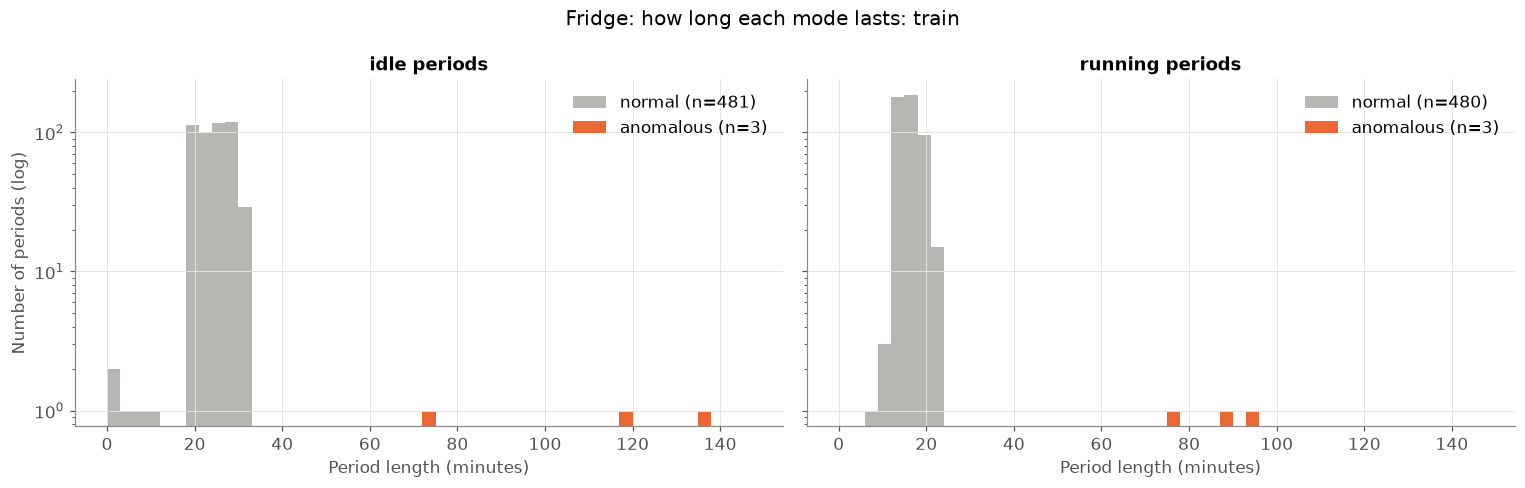

count   min    50%    max
mode    anomalous                           
defrost False       31.0  20.0   20.0   20.0
idle    False      481.0   1.0   24.0   30.0
        True         3.0  72.0  118.0  137.0
running False      480.0   8.0   15.0   22.0
        True         3.0  77.0   87.0   93.0

In [10]:
mode = feat["fridge_mode"]
block = (mode != mode.shift()).cumsum()
runs = pd.DataFrame({
    "mode": mode.groupby(block).first(),
    "minutes": mode.groupby(block).size(),
    "anomalous": (feat["anomaly_sensor"] == cfg.POWER).groupby(block).any(),
}).dropna(subset=["mode"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, m in zip(axes, ["idle", "running"]):
    r = runs[runs["mode"] == m]
    bins = np.arange(0, 150, 3)
    ax.hist(r.loc[~r["anomalous"], "minutes"], bins=bins, color=NORMAL, alpha=0.7,
            label=f"normal (n={int((~r['anomalous']).sum())})")
    ax.hist(r.loc[r["anomalous"], "minutes"], bins=bins, color=ANOMALOUS,
            label=f"anomalous (n={int(r['anomalous'].sum())})")
    ax.set_yscale("log")
    ax.set_title(f"{m} periods")
    ax.set_xlabel("Period length (minutes)")
    ax.legend()
axes[0].set_ylabel("Number of periods (log)")
fig.suptitle("Fridge: how long each mode lasts: train", fontsize=13)
fig.tight_layout()
fig.savefig(OUT_DIR / "4_fridge_run_lengths.png", bbox_inches="tight")
plt.show()

runs.groupby(["mode", "anomalous"])["minutes"].describe()[["count", "min", "50%", "max"]]

## 5. Feature checks

These reproduce the feature numbers quoted in `docs/design.md`. Train only, except check 5.5, which compares feature values mechanically and does not inspect val/test patterns.

In [11]:
# 5.1 temp_resid: normal spread vs spikes
normal_t = feat["anomaly_sensor"] != cfg.TEMP
resid = feat.loc[normal_t, "temp_resid"]
print(f"temp_resid normal: std {resid.std():.2f}, range {resid.min():.2f} to {resid.max():.2f} degC")
print("temp_resid at train spikes:", feat.loc[feat["anomaly_type"] == "temp_spike", "temp_resid"].round(2).tolist())

temp_resid normal: std 0.12, range -0.46 to 0.60 degC
temp_resid at train spikes: [-4.11, 3.62, 3.75, 3.57]


In [12]:
# 5.2 minutes_since_door_open: intrusion vs normal motion in expected-empty hours (Tue-Thu 09-17 h)
moving = feat[cfg.MOTION] == 1
intrusion = feat["anomaly_type"] == "intrusion_motion"
empty_hours = (feat["day_type"] == "tue_thu") & feat["hour"].between(9, 17)
since_intr = feat.loc[moving & intrusion, "minutes_since_door_open"]
since_norm = feat.loc[moving & empty_hours & ~intrusion, "minutes_since_door_open"]
print(f"intrusion motion minutes: {len(since_intr)}, minutes since door open {since_intr.min():.0f} to {since_intr.max():.0f}")
print(f"normal motion Tue-Thu 09-17 h: {len(since_norm)} minutes, <= 5 min since door: {(since_norm <= 5).sum()}, > 30 min: {(since_norm > 30).sum()}")

intrusion motion minutes: 30, minutes since door open 95 to 180
normal motion Tue-Thu 09-17 h: 49 minutes, <= 5 min since door: 28, > 30 min: 5


In [13]:
# 5.3 Baseline contamination: share of heating-failure minutes in each (group, hour) cell
failure = feat["anomaly_type"] == "heating_failure"
worst_3 = failure.groupby([feat["day_type"], feat["hour"]]).mean().max()
worst_2 = failure.groupby([feat["baseline_group"], feat["hour"]]).mean().max()
print(f"worst cell contamination: 3 day types {worst_3:.0%} -> 2 baseline groups {worst_2:.0%}")

worst cell contamination: 3 day types 50% -> 2 baseline groups 25%


In [14]:
# 5.4 Rate noise: raw difference vs rolling mean vs rolling median (stable normal minutes: occupied days, 10-11 h)
temp = feat[cfg.TEMP]
stable = normal_t & (feat["day_type"] != "tue_thu") & feat["hour"].between(10, 11)
rates = {
    "raw difference": (temp - temp.shift(15)) * 4,
    "rolling mean": (lambda s: (s - s.shift(15)) * 4)(temp.rolling(15, min_periods=10).mean()),
    "rolling median (used)": feat["temp_rate_15"],
}
pd.DataFrame({name: {"std on stable minutes (degC/h)": r[stable].std(), "min on normal minutes (degC/h)": r[normal_t].min()}
              for name, r in rates.items()}).round(2)

,raw difference,rolling mean,rolling median (used)
std on stable minutes (degC/h),0.56,0.14,0.18
min on normal minutes (degC/h),-15.72,-2.51,-1.24


In [15]:
# 5.5 Split-start warm-up: first hour of val/test vs one continuous 28-day run
full = F.build_features(F.clean(pd.concat([F.load_split(s) for s in cfg.SPLITS]),
                                cfg.SPLITS["train"][0], cfg.SPLITS["test"][1]), baseline)
rows = []
for split in ["val", "test"]:
    start = pd.Timestamp(cfg.SPLITS[split][0])
    hour = slice(start, start + pd.Timedelta("59min"))
    ref = full.loc[hour].select_dtypes("number").to_numpy(float)
    warm = F.split_features(split, baseline).loc[hour].select_dtypes("number").to_numpy(float)
    cold = F.build_features(F.clean_split(split), baseline).loc[hour].select_dtypes("number").to_numpy(float)
    rows.append({"split": split,
                 "with warm-up identical": bool(np.isclose(warm, ref, equal_nan=True).all()),
                 "without warm-up: NaN cells": int((np.isnan(cold) & ~np.isnan(ref)).sum()),
                 "without warm-up: wrong cells": int((~np.isclose(cold, ref, equal_nan=True)).sum())})
pd.DataFrame(rows)

,split,with warm-up identical,without warm-up: NaN cells,without warm-up: wrong cells
0,val,True,93,128
1,test,True,93,115


## Findings

**Data quality**
- Each split has exactly 2 duplicate rows, 1 hub outage (26 / 40 / 33 missing rows) and no out-of-order timestamps.
- Cleaning finds **2 offline periods per sensor per split** (its own outage plus the hub outage). This matches the generation log exactly. Offline minutes = logged minutes − 2 per outage (the 2-minute forward fill).
- Single dropped readings are all filled by the 2-minute forward fill. None of them become offline periods.

**Anomalies:** 21 / 14 / 14 (train / val / test). 7.3% / 9.8% / 9.2% of split minutes. Heating failure (with recovery) is the largest share.

**What each sensor needs (from plots 2–4)**

| Sensor | Observation | Implication for detection |
|---|---|---|
| Temperature | Tue–Thu daytime runs ~2 °C below other day types (eco mode). Train spikes sit at −4.3 and +3.5 to +3.7 °C deviation (normal −1.8 to +1.5 °C). A weaker spike during a lag could fall inside that range, so `temp_resid` (reading − 15-min rolling median) isolates spikes in any context. Heating failure + recovery spans −2.1 to +0.1 °C, which **overlaps the normal range**. | `temp_resid` catches spikes. Heating failure needs **duration / rate of fall in context**, not one threshold. |
| Fridge | No useful daily pattern in compressor share (0.3–0.55, noisy). Stuck-on power (100–130 W) is the **same as normal running**. Power loss is ≤ 0.6 W vs a normal idle minimum of 1.1 W. | **Mode duration** is the key signal: normal idle ≤ 30 min and running ≤ 22 min, vs anomalous 72–137 and 77–93 min. Time context adds little. |
| Motion | ~0 motion Tue–Thu 09–16 h. Intrusion motion counts (1–9 per 15 min) **overlap normal home activity**. | Intrusion needs **context** (expected empty house) **and** the cross-sensor link: `minutes_since_door_open`, since a real return opens the door first. |
| Door | Normal openings last ≤ 4 min. `door_left_open` lasts up to 41 min (train). `door_open_night` (1–5 min) has a normal duration. | Open duration separates `door_left_open`. `door_open_night` needs **time of day**. |

**Note:** the label-split numbers above are **descriptive only**. Detector thresholds come from physics or from unlabelled train distributions, and are tuned on val.

**Preprocessing confirmed:** no scaling. The temperature baseline is fit on train only (pooled into 2 groups: `tue_thu` vs occupied), with fixed fridge mode thresholds. Context features (hour, day type) matter for temperature, motion and door, but not for the fridge.